# Can Algae Keep a Starship Crew Breathing?

A crew of 15 wakes from hibernation to explore a newly found planetary system. Their air is maintained by a biological life support system: a photobioreactor growing the microalga *Chlorella*, which absorbs the carbon dioxide people breathe out and releases oxygen.

The task: from the reactor's telemetry, check that it is working, and whether it is enough for the crew.

1. The crew's needs: oxygen consumed and carbon dioxide exhaled, per person and for all 15, kg per day.
2. The reactor's capacity: its output of dry chlorella biomass, and the oxygen and carbon dioxide that output corresponds to.
3. The balance between the two.

**Data:** [telemetry.csv](telemetry.csv), a telemetry sample of the reactor (dated 2230: the scenario is fictional).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.figsize": (12, 4.5), "axes.spines.top": False, "axes.spines.right": False})

## 1. The crew's needs

The Russian standard for the habitat of cosmonauts in crewed spacecraft (GOST R 50804-95, section 6.2.2.1) requires the air system to supply **0.86 kg of oxygen** and remove **0.95 kg of carbon dioxide** per person per day (±10%).

In [2]:
CREW = 15
O2_PER_PERSON = 0.86    # kg per day, GOST R 50804-95
CO2_PER_PERSON = 0.95   # kg per day, GOST R 50804-95

crew_o2 = CREW * O2_PER_PERSON
crew_co2 = CREW * CO2_PER_PERSON
print(f"one person: {O2_PER_PERSON} kg O2 consumed, {CO2_PER_PERSON} kg CO2 exhaled per day")
print(f"crew of {CREW}: {crew_o2:.2f} kg O2 consumed, {crew_co2:.2f} kg CO2 exhaled per day")

one person: 0.86 kg O2 consumed, 0.95 kg CO2 exhaled per day
crew of 15: 12.90 kg O2 consumed, 14.25 kg CO2 exhaled per day


## 2. The reactor

### How much gas a gram of chlorella exchanges

Growing chlorella fixes carbon dioxide and releases oxygen in proportion to the biomass it produces. Measured values per gram of dry biomass, depending on the nitrogen source in the growth medium (Meleshko and Shepelev, *Biological Life Support Systems*):

In [3]:
exchange = pd.DataFrame({
    "CO2 absorbed, g per g dry biomass": [1.97, 2.02, 1.94],
    "O2 released, g per g dry biomass": [1.87, 1.55, 1.70],
}, index=["potassium nitrate KNO3", "urea CO(NH2)2", "ammonium nitrate NH4NO3"])
exchange

,"CO2 absorbed, g per g dry biomass","O2 released, g per g dry biomass"
potassium nitrate KNO3,1.97,1.87
urea CO(NH2)2,2.02,1.55
ammonium nitrate NH4NO3,1.94,1.70


The telemetry doesn't say which nitrogen source is used, so the calculation uses potassium nitrate, the most common medium for chlorella; the end of the notebook shows how much the others would change the result.

In [4]:
CO2_PER_G, O2_PER_G = exchange.loc["potassium nitrate KNO3"]

### The telemetry

In [5]:
raw = pd.read_csv("telemetry.csv", sep=";", decimal=",").dropna(axis=1, how="all")
t = raw.rename(columns={"Date and time": "datetime", "Time from start, sec": "seconds", "Time from start2, sec": "process_seconds",
                        "Dry weight, g/L": "density_g_l", "Grow rate, g/L per day": "growth_rate_g_l_day",
                        "Culture temperature, °C": "temperature_c", " CO2 concentration, ppm": "co2_ppm",
                        "Culture mass, kg": "culture_kg", "Air power,%": "air_power_pct", "N_phiks": "n_phiks",
                        "Light power,%": "light_power_pct"})
print(f"{len(t):,} readings")
t.describe().T.round(3)

1,203 readings


,count,mean,std,min,25%,50%,75%,max
seconds,1203.0,530.624,90.783,366.000,453.000,526.000,608.000,686.000
process_seconds,1203.0,25653.205,5432.957,15639.000,20976.500,25308.000,30411.500,34938.000
density_g_l,1203.0,3.020,0.023,2.807,3.008,3.021,3.036,3.047
growth_rate_g_l_day,1203.0,13.386,11.128,-115.591,14.288,14.349,14.423,14.523
temperature_c,1203.0,31.947,0.078,31.818,31.877,31.949,32.013,32.098
co2_ppm,1203.0,45000.000,0.000,45000.000,45000.000,45000.000,45000.000,45000.000
culture_kg,1203.0,972.931,16.082,945.136,958.473,973.470,986.805,1000.142
air_power_pct,1203.0,16.000,0.000,16.000,16.000,16.000,16.000,16.000
n_phiks,1203.0,2.000,0.000,2.000,2.000,2.000,2.000,2.000
light_power_pct,1203.0,20.000,0.000,20.000,20.000,20.000,20.000,20.000


The settings stay fixed throughout: air supply at 16%, light at 20% of full power, and CO2 in the supply gas at 45,000 ppm (4.5%). The second time column runs about 60 times faster than the first, so it looks like process time in an accelerated simulation:

In [6]:
scale = np.polyfit(t.seconds, t.process_seconds, 1)[0]
hours = (t.process_seconds.max() - t.process_seconds.min()) / 3600
print(f"process time runs {scale:.0f}x faster than clock time; the sample covers {hours:.1f} hours of process time")

process time runs 60x faster than clock time; the sample covers 5.4 hours of process time


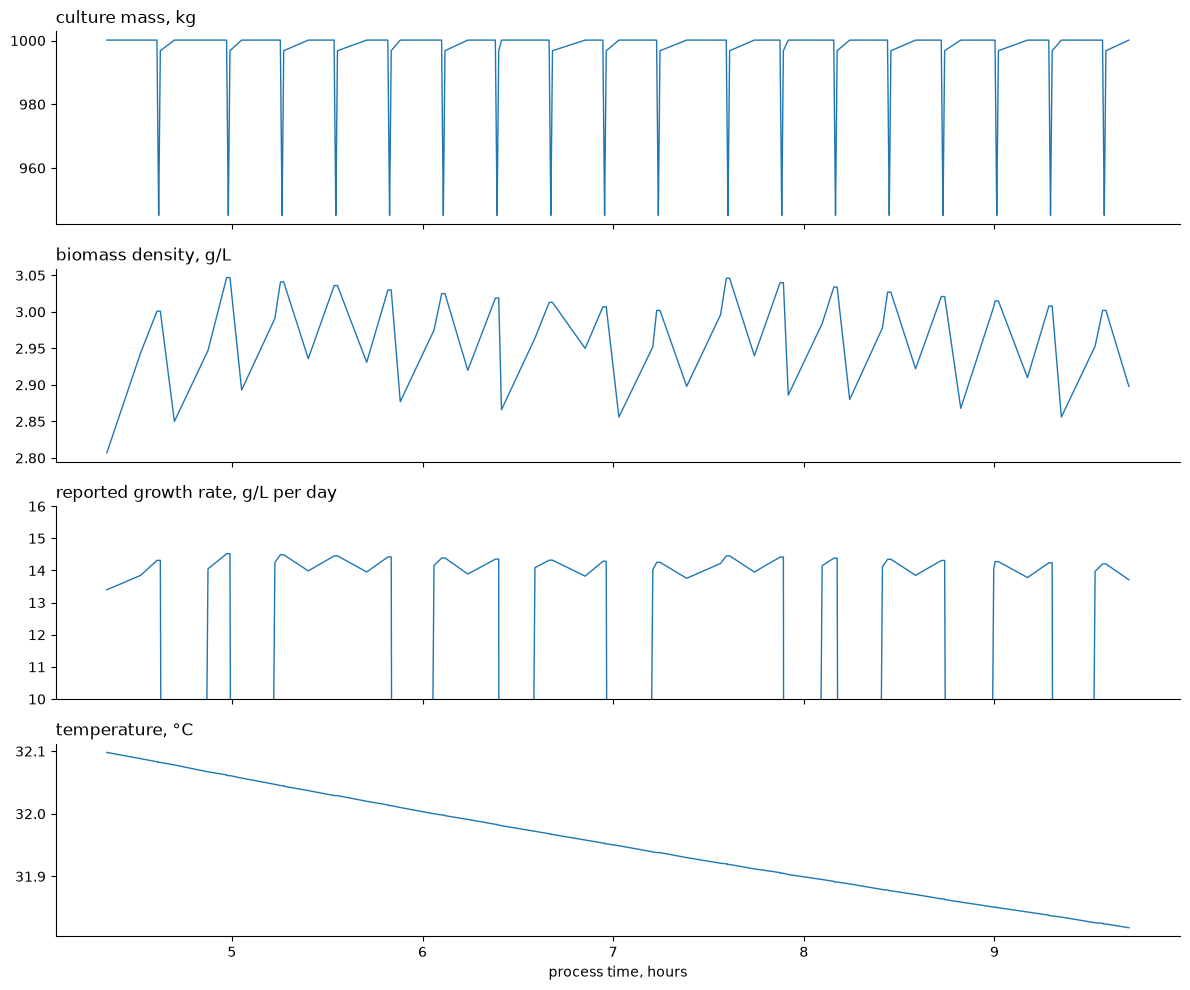

In [7]:
fig, axes = plt.subplots(4, 1, figsize=(12, 10), sharex=True)
x = t.process_seconds / 3600
for ax, col, title in zip(axes, ["culture_kg", "density_g_l", "growth_rate_g_l_day", "temperature_c"],
                          ["culture mass, kg", "biomass density, g/L", "reported growth rate, g/L per day", "temperature, °C"]):
    ax.plot(x, t[col], lw=1)
    ax.set_title(title, loc="left")
axes[2].set_ylim(10, 16)
axes[-1].set_xlabel("process time, hours")
plt.tight_layout()
plt.show()

The reactor runs continuously: culture is drawn off for harvest in small steps of about 1.7 kg while fresh medium is added, so the culture mass swings between about 948 and 1,000 kg. The biomass density stays close to 3.0 g/L, and the temperature near 32 °C. The reported growth rate holds around 14.3 g/L per day, with short dips to about −115 at the moments the reactor is refilled (dilution, not real loss); the chart cuts them off.

### Two ways to measure productivity

**From the growth rate sensor:** productivity = growth rate × culture volume. Chlorella culture is mostly water, so 1 kg ≈ 1 L.

In [8]:
rate_sensor = t.loc[t.growth_rate_g_l_day > 0, "growth_rate_g_l_day"].median()
volume_l = t.culture_kg.mean()
output_sensor = rate_sensor * volume_l / 1000      # kg of dry biomass per day
print(f"median growth rate: {rate_sensor:.2f} g/L per day, average culture volume: {volume_l:.0f} L")
print(f"productivity by the sensor: {output_sensor:.2f} kg of dry biomass per day")

median growth rate: 14.35 g/L per day, average culture volume: 973 L
productivity by the sensor: 13.96 kg of dry biomass per day


**From a mass balance:** in steady operation the density doesn't change, so everything that grows is what gets harvested, plus any change in the biomass held in the reactor. The biomass drawn off is the culture removed × its density.

In [9]:
step = t.culture_kg.diff()
removed = -(step[step < 0] * t.density_g_l[step < 0]).sum() / 1000          # kg of dry biomass drawn off
stock = t.culture_kg * t.density_g_l / 1000                                   # kg of dry biomass in the reactor
change = stock.iloc[-1] - stock.iloc[0]
days = (t.process_seconds.max() - t.process_seconds.min()) / 86_400
output_balance = (removed + change) / days
print(f"biomass drawn off: {removed:.2f} kg, change in the reactor: {change:+.2f} kg, over {days * 24:.1f} hours")
print(f"productivity by mass balance: {output_balance:.2f} kg of dry biomass per day "
      f"({output_balance * 1000 / volume_l:.2f} g/L per day)")
print(f"difference between the two methods: {output_sensor / output_balance - 1:.1%}")

biomass drawn off: 2.99 kg, change in the reactor: +0.09 kg, over 5.4 hours
productivity by mass balance: 13.81 kg of dry biomass per day (14.19 g/L per day)
difference between the two methods: 1.1%


The two methods agree within about 1%: the culture grows by about 14 g/L per day, and the same amount is harvested, which is why the density stays steady. The reactor is working, and its growth sensor can be trusted.

## 3. The balance

In [10]:
rows = {}
for name, output in [("by the growth rate sensor", output_sensor), ("by mass balance", output_balance)]:
    rows[name] = {"dry biomass, kg/day": output, "O2 released, kg/day": output * O2_PER_G, "CO2 absorbed, kg/day": output * CO2_PER_G,
                  "share of crew O2 need": output * O2_PER_G / crew_o2, "share of crew CO2 output": output * CO2_PER_G / crew_co2}
balance = pd.DataFrame(rows).T
balance.round(2)

,"dry biomass, kg/day","O2 released, kg/day","CO2 absorbed, kg/day",share of crew O2 need,share of crew CO2 output
by the growth rate sensor,13.96,26.11,27.5,2.02,1.93
by mass balance,13.81,25.82,27.2,2.00,1.91


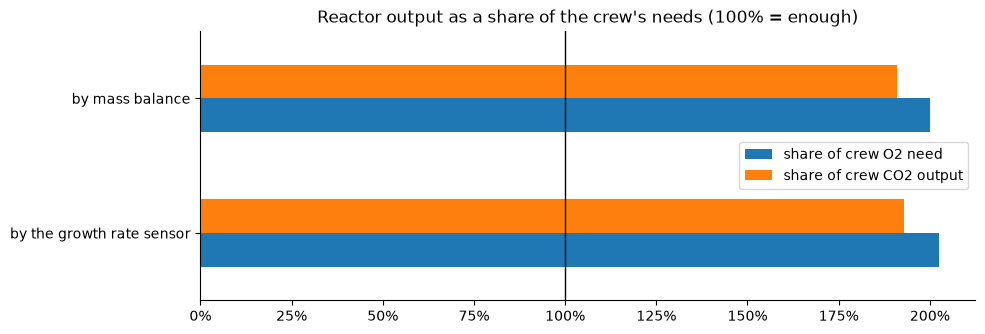

In [11]:
ax = balance[["share of crew O2 need", "share of crew CO2 output"]].plot.barh(figsize=(10, 3.5))
ax.axvline(1, color="black", lw=1)
ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
ax.set_title("Reactor output as a share of the crew's needs (100% = enough)")
plt.show()

In [12]:
needed = crew_o2 / O2_PER_G
print(f"dry biomass needed to cover the crew's oxygen: {needed:.1f} kg/day, "
      f"{needed * 1000 / volume_l:.1f} g/L per day at the current volume")
for source, row in exchange.iterrows():
    print(f"with {source}: the mass-balance output covers {output_balance * row['O2 released, g per g dry biomass'] / crew_o2:.0%} of the oxygen need")

dry biomass needed to cover the crew's oxygen: 6.9 kg/day, 7.1 g/L per day at the current volume
with potassium nitrate KNO3: the mass-balance output covers 200% of the oxygen need
with urea CO(NH2)2: the mass-balance output covers 166% of the oxygen need
with ammonium nitrate NH4NO3: the mass-balance output covers 182% of the oxygen need


## Results

- The crew of 15 needs 12.9 kg of oxygen per day and exhales 14.25 kg of carbon dioxide (0.86 and 0.95 kg per person, by GOST R 50804-95).
- The reactor is working: about 970 L of culture at a steady 3.0 g/L and 32 °C, growing about 14 g/L per day and harvested at the same rate. Two independent estimates, from the growth sensor and from a mass balance of harvested biomass, agree within 1%: about 13.8–14.0 kg of dry biomass per day.
- With potassium nitrate in the medium, that output releases about 26 kg of oxygen and absorbs about 27 kg of carbon dioxide per day, about twice what the crew needs. Even with urea, the least favorable nitrogen source, it covers 166% of the oxygen need. The crew's oxygen alone would take about 6.9 kg of dry biomass per day, half the current output.
- The reactor is enough, with a wide margin, and it runs at only 20% of its light power. It absorbs about twice as much carbon dioxide as the crew exhales, so at this output it relies on the CO2-enriched supply gas (4.5%); with the crew as its only CO2 source, it could run at about half the current output.

## Tools

Python, pandas, NumPy, matplotlib